<a href="https://colab.research.google.com/github/RojaKhondokar/OCD-GWAS-Analysis/blob/main/OCD_GWAS_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Identification and Functional Annotation of OCD-Associated SNPs

**Dataset:** Strom et al. (2025), OCD GWAS summary statistics excluding 23andMe.

**Research question:** Which genetic variants are significantly associated with OCD, and what are their predicted biological functions?

**Week 1 objective:** Load, inspect, and preprocess GWAS summary statistics using Python.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Python libraries imported successfully!")


Python libraries imported successfully!


In [2]:

file_path = "/content/daner_OCD_full_wo23andMe_190522.gz"

# Read only the first five rows
df_preview = pd.read_csv(
    file_path,
    sep="\t",
    compression="gzip",
    nrows=5
)

display(df_preview)


,CHR,SNP,BP,A1,A2,FRQ_A_23493,FRQ_U_1114613,INFO,OR,SE,P,ngt,Direction,HetISqt,HetDf,HetPVa,Nca,Nco,Neff_half
0,8,rs117278216,100516008,T,C,0.983,0.984,0.926,0.99491,0.0458,0.9116,0,-+-+?-?++?---+--?+????+????,0.0,14,0.61240,20570,1036589,34049.58
1,8,rs62513865,101592213,C,T,0.926,0.918,0.967,1.01613,0.0203,0.4319,0,--++-+---++++-+-?-??--+++--,40.6,23,0.02130,23170,1114290,37925.99
2,8,rs79643588,106973048,G,A,0.904,0.895,0.975,0.98916,0.0178,0.5405,0,--++-----+++++++?+--+++--+-,30.2,25,0.07481,23438,1114558,38193.99
3,8,rs17396518,108690829,T,G,0.560,0.557,0.996,0.99223,0.0129,0.5454,0,++?--+----+--?++?+??-++---+,12.9,21,0.28770,17027,652817,25814.81
4,8,rs983166,108681675,A,C,0.562,0.550,0.994,1.00200,0.0128,0.8769,0,++?+-++---+-+?++-++--+++-++,0.0,24,0.83760,17350,653140,26137.81


In [4]:

print("Column names:")
print(df_preview.columns.tolist())

print("\nData types:")
print(df_preview.dtypes)


Column names:
['CHR', 'SNP', 'BP', 'A1', 'A2', 'FRQ_A_23493', 'FRQ_U_1114613', 'INFO', 'OR', 'SE', 'P', 'ngt', 'Direction', 'HetISqt', 'HetDf', 'HetPVa', 'Nca', 'Nco', 'Neff_half']

Data types:
CHR                int64
SNP               object
BP                 int64
A1                object
A2                object
FRQ_A_23493      float64
FRQ_U_1114613    float64
INFO             float64
OR               float64
SE               float64
P                float64
ngt                int64
Direction         object
HetISqt          float64
HetDf              int64
HetPVa           float64
Nca                int64
Nco                int64
Neff_half        float64
dtype: object


In [5]:

# Count SNP records and missing values in chunks

total_rows = 0
missing_values = None

for chunk in pd.read_csv(
    file_path,
    sep="\t",
    compression="gzip",
    chunksize=100000
):
    total_rows += len(chunk)

    if missing_values is None:
        missing_values = chunk.isnull().sum()
    else:
        missing_values += chunk.isnull().sum()

print("Total SNP records:", total_rows)

print("\nMissing values per column:")
print(missing_values)


Total SNP records: 6791632

Missing values per column:
CHR              0
SNP              0
BP               0
A1               0
A2               0
FRQ_A_23493      0
FRQ_U_1114613    0
INFO             0
OR               0
SE               0
P                0
ngt              0
Direction        0
HetISqt          0
HetDf            0
HetPVa           0
Nca              0
Nco              0
Neff_half        0
dtype: int64


In [6]:

invalid_p = 0
invalid_or = 0
invalid_bp = 0
invalid_chr = 0

for chunk in pd.read_csv(
    file_path,
    sep="\t",
    compression="gzip",
    chunksize=100000
):
    invalid_p += (~chunk["P"].between(0, 1) |
                  ~np.isfinite(chunk["P"])).sum()

    invalid_or += ((chunk["OR"] <= 0) |
                   ~np.isfinite(chunk["OR"])).sum()

    invalid_bp += (chunk["BP"] <= 0).sum()

    invalid_chr += (~chunk["CHR"].between(1, 22)).sum()

print("Invalid p-values:", invalid_p)
print("Invalid odds ratios:", invalid_or)
print("Invalid genomic positions:", invalid_bp)
print("Records outside chromosomes 1-22:", invalid_chr)


Invalid p-values: 0
Invalid odds ratios: 0
Invalid genomic positions: 0
Records outside chromosomes 1-22: 0


In [7]:

# Genome-wide significance threshold
threshold = 5e-8

significant_chunks = []

for chunk in pd.read_csv(
    file_path,
    sep="\t",
    compression="gzip",
    chunksize=100000
):
    significant = chunk[chunk["P"] < threshold].copy()

    if not significant.empty:
        significant_chunks.append(significant)

# Combine all significant SNPs
if significant_chunks:
    significant_snps = pd.concat(
        significant_chunks,
        ignore_index=True
    )
else:
    significant_snps = pd.DataFrame(
        columns=df_preview.columns
    )

# Sort by statistical significance
significant_snps = significant_snps.sort_values("P")

print("Genome-wide significant SNP records:",
      len(significant_snps))

print("\nTop 10 most significant SNPs:")
display(
    significant_snps[
        ["CHR", "SNP", "BP", "A1", "A2", "OR", "P"]
    ].head(10)
)


Genome-wide significant SNP records: 3

Top 10 most significant SNPs:


,CHR,SNP,BP,A1,A2,OR,P
0,8,rs13262595,143316970,A,G,1.06705,6.902000e-10
1,8,rs4129585,143312933,A,C,1.06599,9.990000e-10
2,8,rs10098073,143309504,C,A,0.94195,2.992000e-08


In [8]:

# Examine association signals at different thresholds

thresholds = [5e-8, 1e-7, 1e-6, 1e-5]

counts = {t: 0 for t in thresholds}
top_snps = []

for chunk in pd.read_csv(
    file_path,
    sep="\t",
    compression="gzip",
    chunksize=100000
):
    for t in thresholds:
        counts[t] += (chunk["P"] < t).sum()

    top_snps.append(
        chunk.nsmallest(10, "P")
    )

top_snps = (
    pd.concat(top_snps)
    .nsmallest(20, "P")
    .reset_index(drop=True)
)

print("SNP records at different p-value thresholds:")

for t, count in counts.items():
    print(f"P < {t:.0e}: {count:,}")

print("\nTop 20 SNP records:")
display(
    top_snps[
        ["CHR", "SNP", "BP", "OR", "P"]
    ]
)


SNP records at different p-value thresholds:
P < 5e-08: 3
P < 1e-07: 4
P < 1e-06: 148
P < 1e-05: 1,089

Top 20 SNP records:


,CHR,SNP,BP,OR,P
0,8,rs13262595,143316970,1.06705,6.902000e-10
1,8,rs4129585,143312933,1.06599,9.990000e-10
2,8,rs10098073,143309504,0.94195,2.992000e-08
3,6,rs16891315,26111756,1.10087,8.345000e-08
4,6,rs13212652,26099279,1.09977,1.068000e-07
5,6,rs13206501,26110148,1.09966,1.093000e-07
6,2,rs7591784,208501730,1.05781,1.167000e-07
7,2,rs35860033,208505678,1.06769,1.307000e-07
8,2,rs16827242,148123019,1.08546,1.320000e-07
9,6,rs36109883,26133070,1.12042,1.582000e-07


In [9]:

# Select relevant columns for the significant SNPs
results_table = significant_snps[
    ["CHR", "SNP", "BP", "A1", "A2",
     "FRQ_A_23493", "FRQ_U_1114613",
     "INFO", "OR", "SE", "P"]
].copy()

# Save the table as a CSV file
results_table.to_csv(
    "/content/OCD_significant_SNPs.csv",
    index=False
)

print("Results table saved successfully!")

display(results_table)


Results table saved successfully!


,CHR,SNP,BP,A1,A2,FRQ_A_23493,FRQ_U_1114613,INFO,OR,SE,P
0,8,rs13262595,143316970,A,G,0.452,0.434,0.983,1.06705,0.0105,6.902000e-10
1,8,rs4129585,143312933,A,C,0.450,0.430,0.997,1.06599,0.0105,9.990000e-10
2,8,rs10098073,143309504,C,A,0.515,0.530,0.981,0.94195,0.0108,2.992000e-08


In [10]:

# Load the columns needed for the Manhattan plot
plot_df = pd.read_csv(
    file_path,
    sep="\t",
    compression="gzip",
    usecols=["CHR", "BP", "P"]
)

# Remove any invalid p-values for log transformation
plot_df = plot_df[
    (plot_df["P"] > 0) &
    (plot_df["P"] <= 1)
].copy()

# Calculate -log10(p-value)
plot_df["minus_log10_p"] = -np.log10(plot_df["P"])

print("SNP records available for plotting:", len(plot_df))

display(plot_df.head())


SNP records available for plotting: 6791632


,CHR,BP,P,minus_log10_p
0,8,100516008,0.9116,0.040196
1,8,101592213,0.4319,0.364617
2,8,106973048,0.5405,0.267204
3,8,108690829,0.5454,0.263285
4,8,108681675,0.8769,0.057050


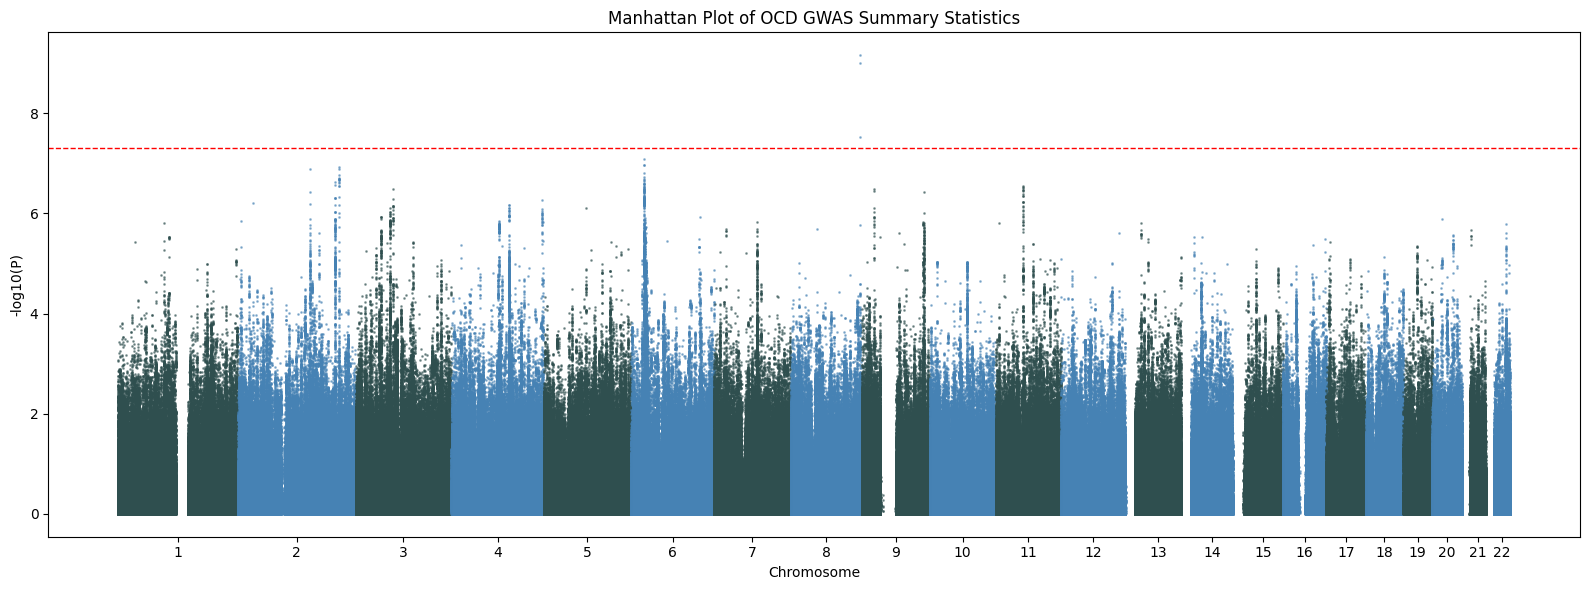

In [11]:

# Sort SNPs by chromosome and position
plot_df = plot_df.sort_values(
    ["CHR", "BP"]
).reset_index(drop=True)

# Calculate chromosome offsets
chromosome_sizes = plot_df.groupby("CHR")["BP"].max()
chromosome_offsets = chromosome_sizes.cumsum().shift(
    fill_value=0
)

# Create cumulative genomic positions
plot_df["plot_position"] = (
    plot_df["BP"] +
    plot_df["CHR"].map(chromosome_offsets)
)

# Calculate chromosome label positions
chromosome_centers = plot_df.groupby("CHR")[
    "plot_position"
].agg(["min", "max"]).mean(axis=1)

# Create the Manhattan plot
fig, ax = plt.subplots(figsize=(16, 6))

for chromosome, group in plot_df.groupby("CHR"):
    ax.scatter(
        group["plot_position"],
        group["minus_log10_p"],
        s=1,
        alpha=0.5,
        color=(
            "steelblue"
            if chromosome % 2 == 0
            else "darkslategray"
        ),
        rasterized=True
    )

# Genome-wide significance threshold
ax.axhline(
    -np.log10(5e-8),
    color="red",
    linestyle="--",
    linewidth=1
)

ax.set_xticks(chromosome_centers.values)
ax.set_xticklabels(chromosome_centers.index)

ax.set_xlabel("Chromosome")
ax.set_ylabel("-log10(P)")
ax.set_title("Manhattan Plot of OCD GWAS Summary Statistics")

plt.tight_layout()

# Save figure
plt.savefig(
    "/content/OCD_Manhattan_Plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


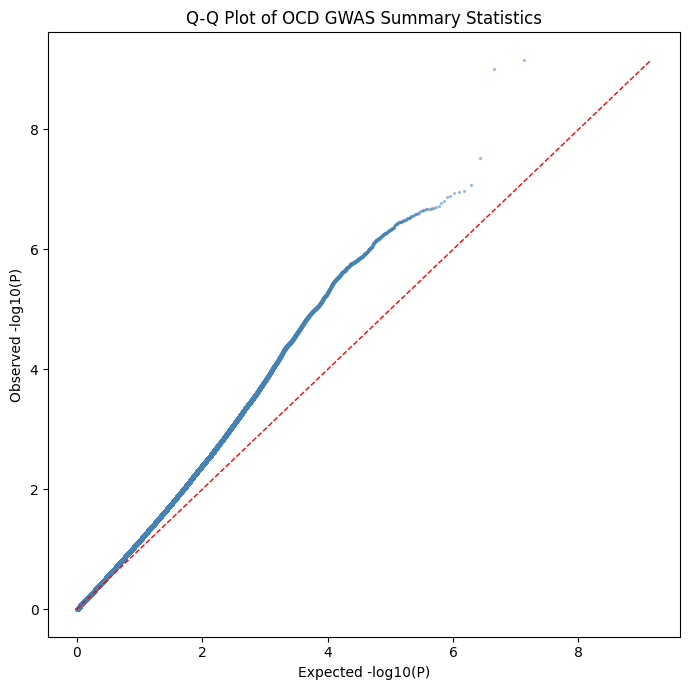

In [12]:

# Sort observed p-values
observed_p = np.sort(plot_df["P"].values)

# Calculate expected p-values under the null hypothesis
n = len(observed_p)

expected_p = (
    np.arange(1, n + 1) - 0.5
) / n

# Convert to -log10 scale
observed_logp = -np.log10(observed_p)
expected_logp = -np.log10(expected_p)

# Create Q-Q plot
fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(
    expected_logp,
    observed_logp,
    s=2,
    alpha=0.4,
    color="steelblue",
    rasterized=True
)

# Expected diagonal
max_value = max(
    expected_logp.max(),
    observed_logp.max()
)

ax.plot(
    [0, max_value],
    [0, max_value],
    "r--",
    linewidth=1
)

ax.set_xlabel("Expected -log10(P)")
ax.set_ylabel("Observed -log10(P)")
ax.set_title("Q-Q Plot of OCD GWAS Summary Statistics")

plt.tight_layout()

plt.savefig(
    "/content/OCD_QQ_Plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [13]:

from scipy.stats import chi2

# Convert GWAS p-values to chi-square statistics
chi_square_values = chi2.isf(
    plot_df["P"].values,
    df=1
)

# Calculate genomic inflation factor
lambda_gc = (
    np.median(chi_square_values) /
    chi2.ppf(0.5, df=1)
)

print("Genomic inflation factor (lambda GC):",
      round(lambda_gc, 4))


Genomic inflation factor (lambda GC): 1.1882


In [14]:

# Check duplicate SNP identifiers across the full dataset

seen_snps = set()
duplicate_count = 0
duplicate_examples = []

for chunk in pd.read_csv(
    file_path,
    sep="\t",
    compression="gzip",
    usecols=["SNP"],
    chunksize=100000
):
    # Identify duplicates within the current chunk
    within_chunk = chunk["SNP"].duplicated()

    # Identify SNPs already encountered in previous chunks
    across_chunks = chunk["SNP"].isin(seen_snps)

    duplicates = chunk.loc[
        within_chunk | across_chunks, "SNP"
    ]

    duplicate_count += len(duplicates)

    # Save a few examples
    if len(duplicate_examples) < 10:
        duplicate_examples.extend(
            duplicates.head(
                10 - len(duplicate_examples)
            ).tolist()
        )

    seen_snps.update(chunk["SNP"])

print("Duplicate SNP records:", duplicate_count)

print("\nExample duplicate SNP identifiers:")
print(duplicate_examples)


Duplicate SNP records: 0

Example duplicate SNP identifiers:
[]


In [15]:

# Validate alleles across the dataset

valid_bases = {"A", "T", "G", "C"}

invalid_allele_count = 0
identical_allele_count = 0
invalid_examples = []

for chunk in pd.read_csv(
    file_path,
    sep="\t",
    compression="gzip",
    usecols=["SNP", "A1", "A2"],
    chunksize=100000
):
    # Check for invalid DNA bases
    invalid = (
        ~chunk["A1"].isin(valid_bases) |
        ~chunk["A2"].isin(valid_bases)
    )

    # Check whether both alleles are identical
    identical = chunk["A1"] == chunk["A2"]

    invalid_allele_count += invalid.sum()
    identical_allele_count += identical.sum()

    if len(invalid_examples) < 10:
        invalid_examples.extend(
            chunk.loc[
                invalid, ["SNP", "A1", "A2"]
            ].head(
                10 - len(invalid_examples)
            ).to_dict("records")
        )

print("Records with invalid alleles:",
      invalid_allele_count)

print("Records with identical A1 and A2:",
      identical_allele_count)

print("\nExamples of invalid alleles:")
print(invalid_examples)


Records with invalid alleles: 0
Records with identical A1 and A2: 0

Examples of invalid alleles:
[]


In [16]:

# Count SNPs by imputation quality

low_info = 0
moderate_info = 0
high_info = 0
invalid_info = 0

for chunk in pd.read_csv(
    file_path,
    sep="\t",
    compression="gzip",
    usecols=["INFO"],
    chunksize=100000
):
    info = chunk["INFO"]

    low_info += (info < 0.8).sum()
    moderate_info += (
        (info >= 0.8) & (info < 0.9)
    ).sum()
    high_info += (
        (info >= 0.9) & (info <= 1)
    ).sum()

    invalid_info += (
        ~np.isfinite(info) |
        (info < 0) |
        (info > 1)
    ).sum()

print("INFO < 0.8:", low_info)
print("INFO 0.8 to < 0.9:", moderate_info)
print("INFO 0.9 to 1.0:", high_info)
print("Invalid INFO scores:", invalid_info)


INFO < 0.8: 0
INFO 0.8 to < 0.9: 103351
INFO 0.9 to 1.0: 6688281
Invalid INFO scores: 0
